In [ ]:
import sys

print(sys.executable)

E:\python_project\Geo\Sample4Geo\Geo761\Scripts\python.exe


In [2]:
import sys, torch

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("PyTorch CUDA build:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

Python: E:\python_project\Geo\Sample4Geo\Geo761\Scripts\python.exe
PyTorch: 2.11.0+cu128
PyTorch CUDA build: 12.8
CUDA available: True
GPU count: 1


In [ ]:
# %pip uninstall -y torch torchvision torchaudio

In [ ]:
# %pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu128

In [5]:
from pathlib import Path
import hashlib
import random

import numpy as np
import pandas as pd

import torch
from torch.utils.data import Dataset, DataLoader

from PIL import Image

from sklearn.model_selection import train_test_split

from sample4geo.model import TimmModel
from sample4geo.transforms import (
    get_transforms_train,
    get_transforms_val
)

E:\python_project\Geo\Sample4Geo\Geo761\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [6]:
# ---------------------------------------------------
# Sample4Geo project
# ---------------------------------------------------

PROJECT_ROOT = Path(
    r"E:\python_project\Geo\Sample4Geo"
)

# ORIGINAL BASELINE CHECKPOINT
# NEVER SAVE TO THIS PATH
BASELINE_CHECKPOINT = (
    PROJECT_ROOT
    / "pretrained"
    / "cvusa"
    / "convnext_base.fb_in22k_ft_in1k_384"
    / "weights_e40_98.6830.pth"
)

# ---------------------------------------------------
# Fine-tuning output directory
# ---------------------------------------------------

FT_DIR = (
    PROJECT_ROOT
    / "FT"
    / "CVIAN_run01"
)

FT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Baseline checkpoint:")
print(BASELINE_CHECKPOINT)

print("\nFine-tuning output:")
print(FT_DIR)

Baseline checkpoint:
E:\python_project\Geo\Sample4Geo\pretrained\cvusa\convnext_base.fb_in22k_ft_in1k_384\weights_e40_98.6830.pth

Fine-tuning output:
E:\python_project\Geo\Sample4Geo\FT\CVIAN_run01


In [7]:
def sha256_file(path):
    sha = hashlib.sha256()

    with open(path, "rb") as f:
        while True:
            chunk = f.read(1024 * 1024)

            if not chunk:
                break

            sha.update(chunk)

    return sha.hexdigest()


baseline_hash = sha256_file(
    BASELINE_CHECKPOINT
)

print("Baseline SHA256:")
print(baseline_hash)

Baseline SHA256:
739cf00d303836fba1195f1bb8d54c4b13c53926ce3212fc9ceced335fc59a23


In [8]:
with open(
    FT_DIR / "baseline_sha256.txt",
    "w"
) as f:
    f.write(baseline_hash)

In [9]:
CVIAN_ROOT = Path(
    r"E:\python_project\Geo\CVIAN"
)

GROUND_ROOT = (
    CVIAN_ROOT
    / "panoroma_split"
    / "00_SVI"
)

SATELLITE_ROOT = (
    CVIAN_ROOT
    / "01_Satellite"
)

print("Ground:", GROUND_ROOT)
print("Satellite:", SATELLITE_ROOT)

Ground: E:\python_project\Geo\CVIAN\panoroma_split\00_SVI
Satellite: E:\python_project\Geo\CVIAN\01_Satellite


In [10]:
allowed_extensions = {
    ".png",
    ".jpg",
    ".jpeg"
}

rows = []


for left_path in GROUND_ROOT.rglob("*_left.*"):

    if left_path.suffix.lower() not in allowed_extensions:
        continue

    # Example:
    # 104078525924854_left
    #          ↓
    # 104078525924854

    pair_id = left_path.stem.removesuffix(
        "_left"
    )

    # Find corresponding right image
    right_path = None

    for ext in allowed_extensions:

        candidate = (
            left_path.parent
            / f"{pair_id}_right{ext}"
        )

        if candidate.exists():
            right_path = candidate
            break


    if right_path is None:
        print(
            "Missing right:",
            pair_id
        )
        continue


    # Damage class / relative folder
    relative_folder = (
        left_path.parent
        .relative_to(GROUND_ROOT)
    )

    # Find corresponding satellite
    satellite_path = None

    satellite_folder = (
        SATELLITE_ROOT
        / relative_folder
    )

    for ext in allowed_extensions:

        candidate = (
            satellite_folder
            / f"{pair_id}{ext}"
        )

        if candidate.exists():
            satellite_path = candidate
            break


    if satellite_path is None:
        print(
            "Missing satellite:",
            pair_id
        )
        continue


    rows.append({
        "pair_id": pair_id,

        "damage_class":
            str(relative_folder),

        "left_path":
            str(left_path),

        "right_path":
            str(right_path),

        "satellite_path":
            str(satellite_path)
    })

In [11]:
manifest = pd.DataFrame(rows)

print(
    "Valid CVIAN locations:",
    len(manifest)
)

display(
    manifest.tail()
)

Valid CVIAN locations: 4121


,pair_id,damage_class,left_path,right_path,satellite_path
4116,992918858569781,2_SevereDamage,E:\python_project\Geo\CVIAN\panoroma_split\00_...,E:\python_project\Geo\CVIAN\panoroma_split\00_...,E:\python_project\Geo\CVIAN\01_Satellite\2_Sev...
4117,993596978488978,2_SevereDamage,E:\python_project\Geo\CVIAN\panoroma_split\00_...,E:\python_project\Geo\CVIAN\panoroma_split\00_...,E:\python_project\Geo\CVIAN\01_Satellite\2_Sev...
4118,996333938050866,2_SevereDamage,E:\python_project\Geo\CVIAN\panoroma_split\00_...,E:\python_project\Geo\CVIAN\panoroma_split\00_...,E:\python_project\Geo\CVIAN\01_Satellite\2_Sev...
4119,997435777936275,2_SevereDamage,E:\python_project\Geo\CVIAN\panoroma_split\00_...,E:\python_project\Geo\CVIAN\panoroma_split\00_...,E:\python_project\Geo\CVIAN\01_Satellite\2_Sev...
4120,998859738218060,2_SevereDamage,E:\python_project\Geo\CVIAN\panoroma_split\00_...,E:\python_project\Geo\CVIAN\panoroma_split\00_...,E:\python_project\Geo\CVIAN\01_Satellite\2_Sev...


In [12]:
manifest.to_csv(
    FT_DIR / "manifest.csv",
    index=False
)

### Split TRAIN / VALIDATION by location

In [13]:
train_df, val_df = train_test_split(
    manifest,
    test_size=0.15,
    random_state=42,
    shuffle=True
)

train_df = train_df.reset_index(
    drop=True
)

val_df = val_df.reset_index(
    drop=True
)

print(
    "Training locations:",
    len(train_df)
)

print(
    "Validation locations:",
    len(val_df)
)

Training locations: 3502
Validation locations: 619


In [14]:
train_df.to_csv(
    FT_DIR / "train.csv",
    index=False
)

val_df.to_csv(
    FT_DIR / "val.csv",
    index=False
)

### Load a NEW model from the baseline checkpoint

In [15]:
device = (
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

model_name = (
    "convnext_base.fb_in22k_ft_in1k_384"
)

finetune_model = TimmModel(
    model_name,
    pretrained=False,
    img_size=384
)

### Load your baseline checkpoint:

In [16]:
state_dict = torch.load(
    BASELINE_CHECKPOINT,
    map_location="cpu"
)

load_result = (
    finetune_model.load_state_dict(
        state_dict,
        strict=False
    )
)

print(
    "Missing keys:",
    load_result.missing_keys
)

print(
    "Unexpected keys:",
    load_result.unexpected_keys
)

Missing keys: []
Unexpected keys: []


In [17]:
finetune_model = (
    finetune_model.to(device)
)

print(
    "Device:",
    device
)

Device: cuda


### get normalization values

In [18]:
data_config = (
    finetune_model.get_config()
)

mean = data_config["mean"]
std = data_config["std"]

print("Mean:", mean)
print("Std:", std)

Mean: (0.485, 0.456, 0.406)
Std: (0.229, 0.224, 0.225)


### define fine-tuning image size

In [19]:
image_size_ground = (
    384,
    384
)

image_size_satellite = (
    384,
    384
)

### create training and validation transforms

In [20]:
sat_transform_train, ground_transform_train = (
    get_transforms_train(
        image_size_satellite,
        image_size_ground,
        mean=mean,
        std=std
    )
)

E:\python_project\Geo\Sample4Geo\sample4geo\transforms.py:39: UserWarning: Argument(s) 'quality_lower, quality_upper' are not valid for transform ImageCompression
  A.ImageCompression(quality_lower=90, quality_upper=100, p=0.5),
E:\python_project\Geo\Sample4Geo\sample4geo\transforms.py:41: UserWarning: Argument(s) 'always_apply' are not valid for transform ColorJitter
  A.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15, hue=0.15, always_apply=False, p=0.5),
E:\python_project\Geo\Sample4Geo\sample4geo\transforms.py:48: UserWarning: Argument(s) 'max_holes, max_height, max_width, min_holes, min_height, min_width' are not valid for transform CoarseDropout
  A.CoarseDropout(max_holes=25,
E:\python_project\Geo\Sample4Geo\sample4geo\transforms.py:63: UserWarning: Argument(s) 'quality_lower, quality_upper' are not valid for transform ImageCompression
  A.ImageCompression(quality_lower=90, quality_upper=100, p=0.5),
E:\python_project\Geo\Sample4Geo\sample4geo\transforms.py:65: UserW

In [21]:
sat_transform_val, ground_transform_val = (
    get_transforms_val(
        image_size_satellite,
        image_size_ground,
        mean=mean,
        std=std
    )
)

### custom CVIAN Dataset
During traning randomly choose left or right database

In [22]:
class CVIANPairDataset(Dataset):

    def __init__(
        self,
        dataframe,
        ground_transform,
        satellite_transform,
        training=True
    ):

        self.df = dataframe.reset_index(
            drop=True
        )

        self.ground_transform = (
            ground_transform
        )

        self.satellite_transform = (
            satellite_transform
        )

        self.training = training


    def __len__(self):

        return len(self.df)


    def __getitem__(self, idx):

        row = self.df.iloc[idx]


        # -------------------------------------------
        # Choose ground view
        # -------------------------------------------

        if self.training:

            # Random left/right each time
            if random.random() < 0.5:

                ground_path = (
                    row["left_path"]
                )

                view = "left"

            else:

                ground_path = (
                    row["right_path"]
                )

                view = "right"


        else:

            # Deterministic validation:
            # alternate left/right by sample
            if idx % 2 == 0:

                ground_path = (
                    row["left_path"]
                )

                view = "left"

            else:

                ground_path = (
                    row["right_path"]
                )

                view = "right"


        satellite_path = (
            row["satellite_path"]
        )


        # -------------------------------------------
        # Load images
        # -------------------------------------------

        ground_img = np.array(
            Image.open(
                ground_path
            ).convert("RGB")
        )

        satellite_img = np.array(
            Image.open(
                satellite_path
            ).convert("RGB")
        )


        # -------------------------------------------
        # Transform
        # -------------------------------------------

        ground_tensor = (
            self.ground_transform(
                image=ground_img
            )["image"]
        )

        satellite_tensor = (
            self.satellite_transform(
                image=satellite_img
            )["image"]
        )


        return {

            "ground":
                ground_tensor,

            "satellite":
                satellite_tensor,

            "pair_id":
                row["pair_id"],

            "view":
                view
        }

### Instantiate datasets

In [25]:
train_dataset = CVIANPairDataset(
    dataframe=train_df,
    ground_transform=
        ground_transform_train,
    satellite_transform=
        sat_transform_train,
    training=True
)

val_dataset = CVIANPairDataset(
    dataframe=val_df,
    ground_transform=
        ground_transform_val,
    satellite_transform=
        sat_transform_val,
    training=False
)

print(
    "Train:",
    len(train_dataset)
)

print(
    "Validation:",
    len(val_dataset)
)

Train: 3502
Validation: 619


### DataLoaders

In [26]:
batch_size = 16

In [27]:
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0,
    pin_memory=True,
    drop_last=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

### inspect ONE batch before training

In [28]:
batch = next(
    iter(train_loader)
)

print(
    "Ground:",
    batch["ground"].shape
)

print(
    "Satellite:",
    batch["satellite"].shape
)

print(
    "Pair IDs:",
    batch["pair_id"][:3]
)

print(
    "Views:",
    batch["view"][:3]
)

Ground: torch.Size([16, 3, 384, 384])
Satellite: torch.Size([16, 3, 384, 384])
Pair IDs: ['568736915338831', '2462266427273846', '925113528556762']
Views: ['right', 'right', 'left']


### test one forward pass

In [30]:
ground_batch = (
    batch["ground"]
    .to(device)
)

satellite_batch = (
    batch["satellite"]
    .to(device)
)

In [31]:
finetune_model.eval()

with torch.inference_mode():

    ground_features = (
        finetune_model(
            ground_batch
        )
    )

    satellite_features = (
        finetune_model(
            satellite_batch
        )
    )


print(
    "Ground embedding:",
    ground_features.shape
)

print(
    "Satellite embedding:",
    satellite_features.shape
)

Ground embedding: torch.Size([16, 1024])
Satellite embedding: torch.Size([16, 1024])


### training configuration and checkpoint safety

In [33]:
from pathlib import Path
import math
import random
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F


# ---------------------------------------------------
# Fine-tuning output paths
# ---------------------------------------------------

BEST_MODEL_PATH = FT_DIR / "best_model.pth"
LAST_MODEL_PATH = FT_DIR / "last_model.pth"
HISTORY_PATH = FT_DIR / "training_history.csv"


# ---------------------------------------------------
# Safety: baseline must NEVER equal FT output
# ---------------------------------------------------

assert str(BASELINE_CHECKPOINT).lower() != str(BEST_MODEL_PATH).lower()
assert str(BASELINE_CHECKPOINT).lower() != str(LAST_MODEL_PATH).lower()


# ---------------------------------------------------
# Reproducibility
# ---------------------------------------------------

seed = 42

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)


# ---------------------------------------------------
# Training configuration
# ---------------------------------------------------

epochs = 10

learning_rate = 1e-5

weight_decay = 0.01

label_smoothing = 0.1

initial_temperature = 0.07

warmup_epochs = 1


print("Fine-tuned models will be saved to:")
print(FT_DIR)

print("\nOriginal baseline remains at:")
print(BASELINE_CHECKPOINT)

Fine-tuned models will be saved to:
E:\python_project\Geo\Sample4Geo\FT\CVIAN_run01

Original baseline remains at:
E:\python_project\Geo\Sample4Geo\pretrained\cvusa\convnext_base.fb_in22k_ft_in1k_384\weights_e40_98.6830.pth


### symmetric InfoNCE loss

In [34]:
criterion = torch.nn.CrossEntropyLoss(
    label_smoothing=label_smoothing
)


# Learnable temperature
logit_scale = torch.nn.Parameter(
    torch.tensor(
        np.log(1.0 / initial_temperature),
        dtype=torch.float32,
        device=device
    )
)


def symmetric_info_nce(
    ground_features,
    satellite_features,
    logit_scale
):

    # L2 normalization
    ground_features = F.normalize(
        ground_features,
        p=2,
        dim=1
    )

    satellite_features = F.normalize(
        satellite_features,
        p=2,
        dim=1
    )

    # Learnable 1 / temperature
    scale = logit_scale.exp().clamp(
        max=100
    )

    # B x B similarity matrix
    logits = (
        scale
        * ground_features
        @ satellite_features.T
    )

    # Correct matches are on diagonal
    labels = torch.arange(
        logits.shape[0],
        device=logits.device
    )

    # Ground -> Satellite
    loss_g2s = criterion(
        logits,
        labels
    )

    # Satellite -> Ground
    loss_s2g = criterion(
        logits.T,
        labels
    )

    # Symmetric loss
    loss = (
        loss_g2s + loss_s2g
    ) / 2

    return loss

### optimizer

In [35]:
optimizer = torch.optim.AdamW(
    [
        {
            "params":
                finetune_model.parameters()
        },

        {
            "params":
                [logit_scale],

            "weight_decay":
                0.0
        }
    ],
    lr=learning_rate,
    weight_decay=weight_decay
)


print(
    "Learning rate:",
    learning_rate
)

print(
    "Initial temperature:",
    1 / logit_scale.exp().item()
)

Learning rate: 1e-05
Initial temperature: 0.0699999959945681


### cosine scheduler with warm-up

In [36]:
total_steps = (
    len(train_loader)
    * epochs
)

warmup_steps = (
    len(train_loader)
    * warmup_epochs
)


def lr_lambda(current_step):

    # Warm-up
    if current_step < warmup_steps:

        return float(
            current_step + 1
        ) / float(
            max(1, warmup_steps)
        )

    # Cosine decay
    progress = (
        current_step - warmup_steps
    ) / (
        total_steps - warmup_steps
    )

    return 0.5 * (
        1.0
        + math.cos(
            math.pi * progress
        )
    )


scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda
)


print("Training steps:", total_steps)
print("Warm-up steps:", warmup_steps)

Training steps: 2180
Warm-up steps: 218


mixed precision - saves a lot of VRAM and should speed things up on GPU

In [37]:
use_amp = (
    torch.cuda.is_available()
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=use_amp
)

print(
    "Mixed precision:",
    use_amp
)

Mixed precision: True


### validation retrieval function

In [38]:
def evaluate_retrieval(
    model,
    dataloader,
    device
):

    model.eval()

    all_ground = []
    all_satellite = []

    with torch.inference_mode():

        for batch in dataloader:

            ground = batch[
                "ground"
            ].to(
                device,
                non_blocking=True
            )

            satellite = batch[
                "satellite"
            ].to(
                device,
                non_blocking=True
            )


            with torch.amp.autocast(
                "cuda",
                enabled=use_amp
            ):

                ground_features = model(
                    ground
                )

                satellite_features = model(
                    satellite
                )


            ground_features = F.normalize(
                ground_features,
                p=2,
                dim=1
            )

            satellite_features = F.normalize(
                satellite_features,
                p=2,
                dim=1
            )


            all_ground.append(
                ground_features.cpu()
            )

            all_satellite.append(
                satellite_features.cpu()
            )


    # -----------------------------------------------
    # Combine all validation batches
    # -----------------------------------------------

    all_ground = torch.cat(
        all_ground,
        dim=0
    )

    all_satellite = torch.cat(
        all_satellite,
        dim=0
    )


    # -----------------------------------------------
    # Full query × reference similarity matrix
    # -----------------------------------------------

    similarity_matrix = (
        all_ground
        @ all_satellite.T
    )


    n = similarity_matrix.shape[0]

    correct_indices = torch.arange(n)


    recalls = {}

    for k in [1, 5, 10]:

        actual_k = min(
            k,
            n
        )

        top_k = (
            similarity_matrix
            .topk(
                actual_k,
                dim=1
            )
            .indices
        )

        correct = (
            top_k
            == correct_indices[:, None]
        ).any(dim=1)

        recalls[k] = (
            correct.float()
            .mean()
            .item()
        )


    # Mean similarity of actual positive pairs
    positive_similarity = (
        similarity_matrix
        .diagonal()
        .mean()
        .item()
    )


    return (
        recalls,
        positive_similarity
    )

### measure CVUSA baseline on CVIAN BEFORE training

In [39]:
baseline_recalls, baseline_positive_sim = (
    evaluate_retrieval(
        finetune_model,
        val_loader,
        device
    )
)


print("Before fine-tuning")
print("------------------")

print(
    f"Recall@1:  "
    f"{baseline_recalls[1]:.4f}"
)

print(
    f"Recall@5:  "
    f"{baseline_recalls[5]:.4f}"
)

print(
    f"Recall@10: "
    f"{baseline_recalls[10]:.4f}"
)

print(
    f"Mean positive similarity: "
    f"{baseline_positive_sim:.4f}"
)

Before fine-tuning
------------------
Recall@1:  0.0145
Recall@5:  0.0501
Recall@10: 0.1018
Mean positive similarity: 0.1976


### actual training loop

In [40]:
history = []

best_recall1 = -1.0


for epoch in range(
    1,
    epochs + 1
):

    # ===============================================
    # TRAIN
    # ===============================================

    finetune_model.train()

    running_loss = 0.0


    for step, batch in enumerate(
        train_loader,
        start=1
    ):

        ground = batch[
            "ground"
        ].to(
            device,
            non_blocking=True
        )

        satellite = batch[
            "satellite"
        ].to(
            device,
            non_blocking=True
        )


        optimizer.zero_grad(
            set_to_none=True
        )


        # -------------------------------------------
        # Forward pass
        # -------------------------------------------

        with torch.amp.autocast(
            "cuda",
            enabled=use_amp
        ):

            ground_features = (
                finetune_model(
                    ground
                )
            )

            satellite_features = (
                finetune_model(
                    satellite
                )
            )


            loss = symmetric_info_nce(
                ground_features,
                satellite_features,
                logit_scale
            )


        # -------------------------------------------
        # Backpropagation
        # -------------------------------------------

        scaler.scale(
            loss
        ).backward()


        scaler.step(
            optimizer
        )

        scaler.update()

        scheduler.step()


        running_loss += (
            loss.item()
        )


        # Print progress occasionally
        if (
            step % 50 == 0
            or step == len(train_loader)
        ):

            print(
                f"Epoch {epoch:02d}/{epochs} | "
                f"Step {step:04d}/{len(train_loader)} | "
                f"Loss {loss.item():.4f}"
            )


    average_train_loss = (
        running_loss
        / len(train_loader)
    )


    # ===============================================
    # VALIDATE
    # ===============================================

    recalls, positive_sim = (
        evaluate_retrieval(
            finetune_model,
            val_loader,
            device
        )
    )


    recall1 = recalls[1]
    recall5 = recalls[5]
    recall10 = recalls[10]


    current_lr = (
        optimizer
        .param_groups[0]["lr"]
    )


    temperature = (
        1 /
        logit_scale.exp().item()
    )


    # ===============================================
    # HISTORY
    # ===============================================

    history.append({

        "epoch":
            epoch,

        "train_loss":
            average_train_loss,

        "recall@1":
            recall1,

        "recall@5":
            recall5,

        "recall@10":
            recall10,

        "positive_similarity":
            positive_sim,

        "learning_rate":
            current_lr,

        "temperature":
            temperature
    })


    print(
        "\n"
        f"Epoch {epoch:02d} complete\n"
        f"Train loss: {average_train_loss:.4f}\n"
        f"Recall@1:   {recall1:.4f}\n"
        f"Recall@5:   {recall5:.4f}\n"
        f"Recall@10:  {recall10:.4f}\n"
        f"Positive similarity: {positive_sim:.4f}\n"
        f"Temperature: {temperature:.4f}\n"
    )


    # ===============================================
    # SAVE BEST MODEL
    # ===============================================

    if recall1 > best_recall1:

        best_recall1 = recall1

        torch.save(
            finetune_model.state_dict(),
            BEST_MODEL_PATH
        )

        print(
            "✓ New best model saved:"
        )

        print(
            BEST_MODEL_PATH
        )


    # Save history after every epoch
    pd.DataFrame(
        history
    ).to_csv(
        HISTORY_PATH,
        index=False
    )


# ===================================================
# SAVE LAST MODEL
# ===================================================

torch.save(
    finetune_model.state_dict(),
    LAST_MODEL_PATH
)

print("\nTraining finished.")

print(
    "Best Recall@1:",
    best_recall1
)

print(
    "Best model:",
    BEST_MODEL_PATH
)

print(
    "Last model:",
    LAST_MODEL_PATH
)

Epoch 01/10 | Step 0050/218 | Loss 2.5489
Epoch 01/10 | Step 0100/218 | Loss 2.3756
Epoch 01/10 | Step 0150/218 | Loss 2.1756
Epoch 01/10 | Step 0200/218 | Loss 1.6716
Epoch 01/10 | Step 0218/218 | Loss 2.0015

Epoch 01 complete
Train loss: 2.3548
Recall@1:   0.0759
Recall@5:   0.1987
Recall@10:  0.2989
Positive similarity: 0.3030
Temperature: 0.0700

✓ New best model saved:
E:\python_project\Geo\Sample4Geo\FT\CVIAN_run01\best_model.pth
Epoch 02/10 | Step 0050/218 | Loss 1.4318
Epoch 02/10 | Step 0100/218 | Loss 1.2807
Epoch 02/10 | Step 0150/218 | Loss 1.6701
Epoch 02/10 | Step 0200/218 | Loss 1.2362
Epoch 02/10 | Step 0218/218 | Loss 1.3187

Epoch 02 complete
Train loss: 1.5992
Recall@1:   0.1696
Recall@5:   0.4055
Recall@10:  0.5331
Positive similarity: 0.3988
Temperature: 0.0698

✓ New best model saved:
E:\python_project\Geo\Sample4Geo\FT\CVIAN_run01\best_model.pth
Epoch 03/10 | Step 0050/218 | Loss 1.4387
Epoch 03/10 | Step 0100/218 | Loss 1.3355
Epoch 03/10 | Step 0150/218 | Loss

### plot training results

In [41]:
history_df = pd.DataFrame(
    history
)

display(history_df)

,epoch,train_loss,recall@1,recall@5,recall@10,positive_similarity,learning_rate,temperature
0,1,2.354815,0.075929,0.198708,0.298869,0.303012,1.000000e-05,0.069959
1,2,1.599180,0.169628,0.405493,0.533118,0.398846,9.698463e-06,0.069815
2,3,1.237029,0.224556,0.513732,0.646204,0.422791,8.830222e-06,0.069713
3,4,1.100031,0.268174,0.579968,0.715670,0.432362,7.500000e-06,0.069636
4,5,1.010709,0.303716,0.617124,0.743134,0.433036,5.868241e-06,0.069577
5,6,0.962431,0.319871,0.633280,0.768982,0.430627,4.131759e-06,0.069534
6,7,0.934554,0.326333,0.647819,0.780291,0.430703,2.500000e-06,0.069505
7,8,0.914336,0.339257,0.655897,0.798061,0.428315,1.169778e-06,0.069488
8,9,0.900496,0.340872,0.654281,0.799677,0.427720,3.015369e-07,0.069482
9,10,0.906202,0.340872,0.654281,0.801292,0.427701,0.000000e+00,0.069481


### Training loss:

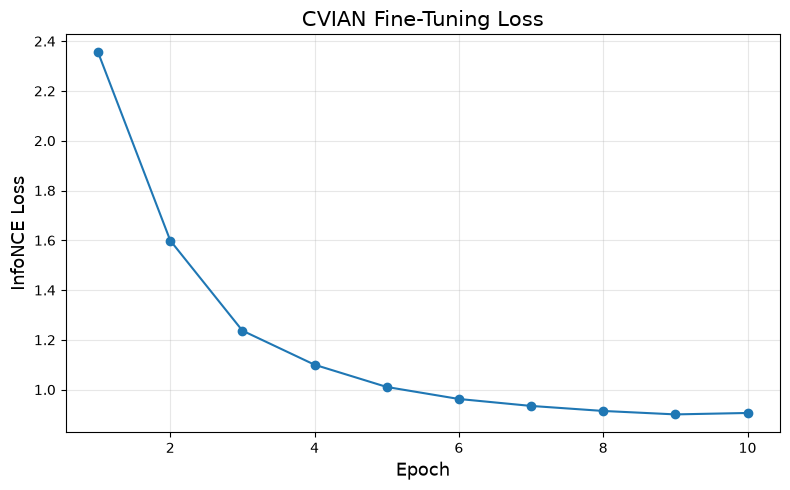

In [42]:
import matplotlib.pyplot as plt


plt.figure(figsize=(8, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o"
)

plt.xlabel(
    "Epoch",
    fontsize=13
)

plt.ylabel(
    "InfoNCE Loss",
    fontsize=13
)

plt.title(
    "CVIAN Fine-Tuning Loss",
    fontsize=15
)

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Retrieval performance:

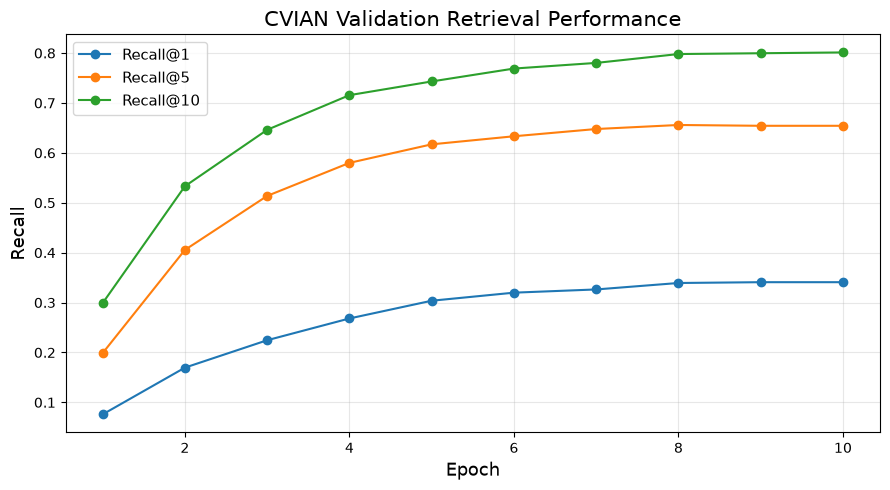

In [43]:
plt.figure(figsize=(9, 5))

plt.plot(
    history_df["epoch"],
    history_df["recall@1"],
    marker="o",
    label="Recall@1"
)

plt.plot(
    history_df["epoch"],
    history_df["recall@5"],
    marker="o",
    label="Recall@5"
)

plt.plot(
    history_df["epoch"],
    history_df["recall@10"],
    marker="o",
    label="Recall@10"
)

plt.xlabel(
    "Epoch",
    fontsize=13
)

plt.ylabel(
    "Recall",
    fontsize=13
)

plt.title(
    "CVIAN Validation Retrieval Performance",
    fontsize=15
)

plt.legend(fontsize=11)

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### verify baseline checkpoint was untouched

In [44]:
baseline_hash_after = sha256_file(
    BASELINE_CHECKPOINT
)

print(
    "Before:",
    baseline_hash
)

print(
    "After: ",
    baseline_hash_after
)

print(
    "\nBaseline unchanged:",
    baseline_hash == baseline_hash_after
)

Before: 739cf00d303836fba1195f1bb8d54c4b13c53926ce3212fc9ceced335fc59a23
After:  739cf00d303836fba1195f1bb8d54c4b13c53926ce3212fc9ceced335fc59a23

Baseline unchanged: True


### load the best fine-tuned checkpoint

In [51]:
BEST_MODEL_PATH = (
    Path(r"E:\python_project\Geo\Sample4Geo\FT\CVIAN_run01")
    / "best_model.pth"
)

state_dict = torch.load(
    BEST_MODEL_PATH,
    map_location="cpu"
)

finetune_model.load_state_dict(
    state_dict,
    strict=True
)

finetune_model = finetune_model.to(device)
finetune_model.eval()

print("Loaded:", BEST_MODEL_PATH)

Loaded: E:\python_project\Geo\Sample4Geo\FT\CVIAN_run01\best_model.pth


In [52]:
from sample4geo.transforms import get_transforms_val

data_config = finetune_model.get_config()

mean = data_config["mean"]
std = data_config["std"]

image_size_ground = (384, 384)
image_size_satellite = (384, 384)

sat_transform_val, ground_transform_val = get_transforms_val(
    image_size_satellite,
    image_size_ground,
    mean=mean,
    std=std
)

In [53]:
def get_embedding(image_path, transform):

    img = np.array(
        Image.open(image_path).convert("RGB")
    )

    tensor = transform(
        image=img
    )["image"]

    tensor = tensor.unsqueeze(0).to(device)

    with torch.inference_mode():

        embedding = finetune_model(
            tensor
        )

        embedding = F.normalize(
            embedding,
            p=2,
            dim=1
        )

    return embedding

### calculate satellite embeddings

In [54]:
satellite_embeddings = {}

for sat_path in satellite_files:

    satellite_embedding = get_embedding(
        sat_path,
        sat_transform_val
    )

    satellite_embeddings[
        sat_path.name
    ] = satellite_embedding

print(
    "Satellite embeddings completed:",
    len(satellite_embeddings)
)

Satellite embeddings completed: 8


### compare all four ground-query types

In [55]:
satellite_files = []

for extension in ["*.png", "*.jpg", "*.jpeg"]:

    satellite_files.extend(
        satellite_folder.glob(extension)
    )

satellite_files = sorted(satellite_files)

print(
    "Number of satellite images:",
    len(satellite_files)
)

for path in satellite_files:
    print(path.name)

Number of satellite images: 8
104078525924854.png
GABRIELLE_HAWKESBAY_SATELLITEV.png
GABRIELLE_HAWKESBAY_SATELLITEV2.png
GABRIELLE_HAWKESBAY_SATELLITEV3.png
GABRIELLE_HAWKESBAY_SATELLITEV4.png
LongBay_SATELLITE.jpg
Okura_SATELLITE.jpg
RodneyWard_SATELLITE.jpg


In [56]:
results_ft = []

for query_type, ground_path in query_groups.items():

    print(f"\nProcessing: {query_type}")

    ground_embedding = get_embedding(
        ground_path,
        ground_transform_val
    )

    for sat_name, sat_embedding in satellite_embeddings.items():

        similarity = (
            ground_embedding
            @ sat_embedding.T
        ).item()

        results_ft.append({
            "query_type": query_type,
            "ground_image": ground_path.name,
            "satellite_image": sat_name,
            "cosine_similarity": similarity
        })

        print(
            f"{sat_name:45s} "
            f"{similarity:.4f}"
        )


Processing: Positive
104078525924854.png                           0.0986
GABRIELLE_HAWKESBAY_SATELLITEV.png            0.4330
GABRIELLE_HAWKESBAY_SATELLITEV2.png           0.2266
GABRIELLE_HAWKESBAY_SATELLITEV3.png           0.3826
GABRIELLE_HAWKESBAY_SATELLITEV4.png           0.4629
LongBay_SATELLITE.jpg                         0.1819
Okura_SATELLITE.jpg                           0.2024
RodneyWard_SATELLITE.jpg                      0.2626

Processing: Easy Negative
104078525924854.png                           0.0201
GABRIELLE_HAWKESBAY_SATELLITEV.png            0.4271
GABRIELLE_HAWKESBAY_SATELLITEV2.png           0.2828
GABRIELLE_HAWKESBAY_SATELLITEV3.png           0.3865
GABRIELLE_HAWKESBAY_SATELLITEV4.png           0.4098
LongBay_SATELLITE.jpg                         0.2515
Okura_SATELLITE.jpg                           0.1042
RodneyWard_SATELLITE.jpg                      0.1423

Processing: Random Negative
104078525924854.png                           0.2166
GABRIELLE_HAWKESBAY_S

### create the DataFrame

In [57]:
df_ft = pd.DataFrame(
    results_ft
)

display(df_ft)

,query_type,ground_image,satellite_image,cosine_similarity
0,Positive,GABRIELLE_HAWKESBAY_CROSSV.png,104078525924854.png,0.098614
1,Positive,GABRIELLE_HAWKESBAY_CROSSV.png,GABRIELLE_HAWKESBAY_SATELLITEV.png,0.432983
2,Positive,GABRIELLE_HAWKESBAY_CROSSV.png,GABRIELLE_HAWKESBAY_SATELLITEV2.png,0.226586
3,Positive,GABRIELLE_HAWKESBAY_CROSSV.png,GABRIELLE_HAWKESBAY_SATELLITEV3.png,0.382639
4,Positive,GABRIELLE_HAWKESBAY_CROSSV.png,GABRIELLE_HAWKESBAY_SATELLITEV4.png,0.462861
5,Positive,GABRIELLE_HAWKESBAY_CROSSV.png,LongBay_SATELLITE.jpg,0.181894
6,Positive,GABRIELLE_HAWKESBAY_CROSSV.png,Okura_SATELLITE.jpg,0.202387
7,Positive,GABRIELLE_HAWKESBAY_CROSSV.png,RodneyWard_SATELLITE.jpg,0.262567
8,Easy Negative,Easy_negative.png,104078525924854.png,0.020149
9,Easy Negative,Easy_negative.png,GABRIELLE_HAWKESBAY_SATELLITEV.png,0.427092


### convert to the similarity matrix

In [58]:
heatmap_ft = df_ft.pivot(
    index="query_type",
    columns="satellite_image",
    values="cosine_similarity"
)

row_order = [
    "Positive",
    "Easy Negative",
    "Random Negative",
    "Hard Negative"
]

heatmap_ft = heatmap_ft.reindex(
    row_order
)

display(heatmap_ft)

satellite_image,104078525924854.png,GABRIELLE_HAWKESBAY_SATELLITEV.png,GABRIELLE_HAWKESBAY_SATELLITEV2.png,GABRIELLE_HAWKESBAY_SATELLITEV3.png,GABRIELLE_HAWKESBAY_SATELLITEV4.png,LongBay_SATELLITE.jpg,Okura_SATELLITE.jpg,RodneyWard_SATELLITE.jpg
query_type,,,,,,,,
Positive,0.098614,0.432983,0.226586,0.382639,0.462861,0.181894,0.202387,0.262567
Easy Negative,0.020149,0.427092,0.282807,0.386468,0.409809,0.251473,0.104207,0.142296
Random Negative,0.216643,0.389921,0.345769,0.419058,0.325716,0.202915,0.139357,0.156744
Hard Negative,0.013775,0.299641,0.224837,0.174957,0.209307,0.114865,0.204884,0.130881


### draw the same green/yellow heatmap

In [59]:
from matplotlib.colors import LinearSegmentedColormap

custom_cmap = LinearSegmentedColormap.from_list(
    "yellow_green",
    [
        "#FFFF33",   # bright yellow - lower similarity
        "#ADFF2F",   # yellow-green
        "#66FF66",   # light green
        "#00FF00"    # bright green - higher similarity
    ]
)

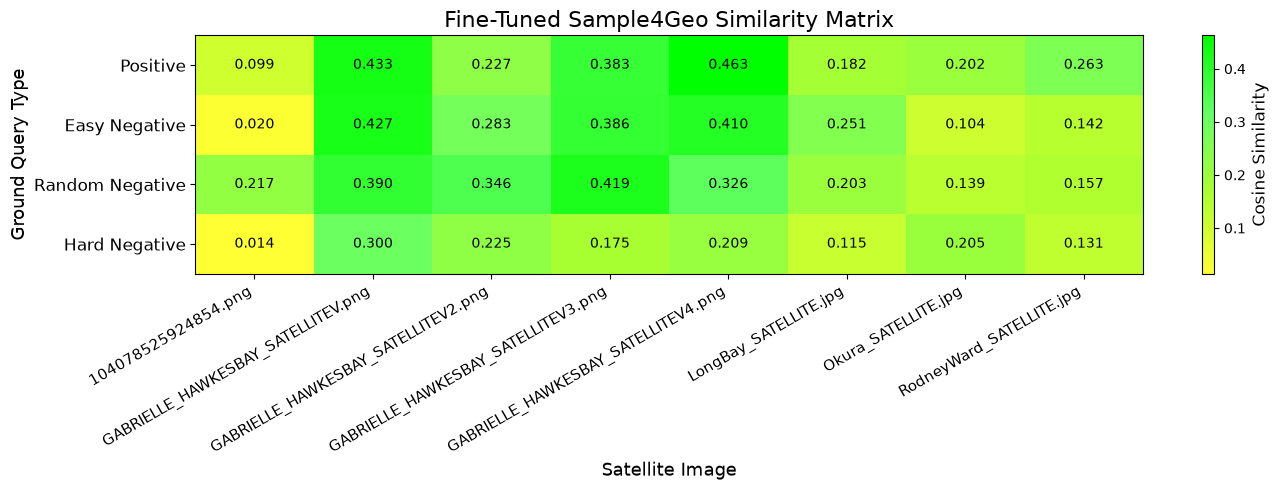

In [60]:
plt.figure(
    figsize=(14, 5)
)

im = plt.imshow(
    heatmap_ft.values,
    aspect="auto",
    cmap=custom_cmap
)

plt.xticks(
    ticks=range(
        len(heatmap_ft.columns)
    ),
    labels=heatmap_ft.columns,
    rotation=30,
    ha="right",
    fontsize=11
)

plt.yticks(
    ticks=range(
        len(heatmap_ft.index)
    ),
    labels=heatmap_ft.index,
    fontsize=12
)

plt.title(
    "Fine-Tuned Sample4Geo Similarity Matrix",
    fontsize=16
)

plt.xlabel(
    "Satellite Image",
    fontsize=13
)

plt.ylabel(
    "Ground Query Type",
    fontsize=13
)

cbar = plt.colorbar(im)

cbar.set_label(
    "Cosine Similarity",
    fontsize=12
)

# Numeric values
for i in range(
    heatmap_ft.shape[0]
):

    for j in range(
        heatmap_ft.shape[1]
    ):

        value = heatmap_ft.values[
            i,
            j
        ]

        plt.text(
            j,
            i,
            f"{value:.3f}",
            ha="center",
            va="center",
            fontsize=10,
            color="black"
        )

plt.tight_layout()

plt.show()